# Analyse exploratoire et classification de chansons Spotify

Projet académique de Data Mining consacré aux caractéristiques audio, à la segmentation non supervisée et à la classification supervisée.

| | |
|---|---|
| **Données** | `genres_v2.csv` — 42 305 lignes, 22 colonnes, 15 genres |
| **Variables audio** | 9 caractéristiques numériques |
| **Méthodes** | ACP, K-Means, corrélations, régression linéaire, LDA, arbre de décision |
| **Reproductibilité** | Graine aléatoire fixe ; séparation supervisée par identifiant de piste |

> La classification évaluée porte uniquement sur les cinq genres les plus fréquents. Les identifiants associés à plusieurs genres sont exclus de cette évaluation.


---
## Phase 1 — Compréhension du problème

**Problématique :** étudier si les caractéristiques audio permettent de décrire des profils de chansons et de distinguer certains genres musicaux.

**Objectifs :**
1. Explorer la structure des données et les genres représentés.
2. Réduire les variables audio avec une analyse en composantes principales (ACP).
3. Rechercher des groupes de profils similaires avec K-Means.
4. Décrire les corrélations entre variables, sans en déduire de causalité.
5. Estimer le niveau de loudness à partir des autres variables audio.
6. Comparer LDA et arbre de décision sur les cinq genres les plus fréquents.

**Critères d’évaluation :** variance expliquée pour l’ACP, inertie et silhouette pour le clustering, R² et RMSE pour la régression, accuracy et F1 macro pour la classification. Les résultats restent exploratoires et ne représentent pas une validation en production.


---
## Phase 2 — Compréhension des données


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_squared_error,
    r2_score,
    silhouette_score,
)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LinearRegression

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.style.use("ggplot")
sns.set_context("notebook")

FEATURES = [
    "danceability", "energy", "loudness", "tempo", "valence",
    "acousticness", "speechiness", "instrumentalness", "liveness",
]
TARGET = "genre"
DATA_PATH = Path.cwd() / "genres_v2.csv"

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Fichier introuvable : {DATA_PATH}. Lancez le notebook depuis le dossier du projet."
    )

df = pd.read_csv(DATA_PATH, low_memory=False)

print("=== APERÇU DES DONNÉES ===")
print(f"Nombre de lignes : {df.shape[0]:,}")
print(f"Nombre de colonnes : {df.shape[1]}")
print("\nColonnes disponibles :")
print(df.columns.tolist())
print("\nTypes des colonnes :")
print(df.dtypes)


=== APERÇU DES DONNÉES ===
Nombre de lignes : 42,305
Nombre de colonnes : 22

Colonnes disponibles :
['danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'type', 'id', 'uri', 'track_href', 'analysis_url', 'duration_ms', 'time_signature', 'genre', 'song_name', 'Unnamed: 0', 'title']

Types des colonnes :
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
type                    str
id                      str
uri                     str
track_href              str
analysis_url            str
duration_ms           int64
time_signature        int64
genre                   str
song_name               str
Unnamed: 0          float64
title                  

In [2]:
print("=== PREMIÈRES LIGNES ===")
df.head()

=== PREMIÈRES LIGNES ===


,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,...,id,uri,track_href,analysis_url,duration_ms,time_signature,genre,song_name,Unnamed: 0,title
0,0.831,0.814,2,-7.364,1,0.4200,0.0598,0.013400,0.0556,0.3890,...,2Vc6NJ9PW9gD9q343XFRKx,spotify:track:2Vc6NJ9PW9gD9q343XFRKx,https://api.spotify.com/v1/tracks/2Vc6NJ9PW9gD...,https://api.spotify.com/v1/audio-analysis/2Vc6...,124539,4,Dark Trap,Mercury: Retrograde,NaN,NaN
1,0.719,0.493,8,-7.230,1,0.0794,0.4010,0.000000,0.1180,0.1240,...,7pgJBLVz5VmnL7uGHmRj6p,spotify:track:7pgJBLVz5VmnL7uGHmRj6p,https://api.spotify.com/v1/tracks/7pgJBLVz5Vmn...,https://api.spotify.com/v1/audio-analysis/7pgJ...,224427,4,Dark Trap,Pathology,NaN,NaN
2,0.850,0.893,5,-4.783,1,0.0623,0.0138,0.000004,0.3720,0.0391,...,0vSWgAlfpye0WCGeNmuNhy,spotify:track:0vSWgAlfpye0WCGeNmuNhy,https://api.spotify.com/v1/tracks/0vSWgAlfpye0...,https://api.spotify.com/v1/audio-analysis/0vSW...,98821,4,Dark Trap,Symbiote,NaN,NaN
3,0.476,0.781,0,-4.710,1,0.1030,0.0237,0.000000,0.1140,0.1750,...,0VSXnJqQkwuH2ei1nOQ1nu,spotify:track:0VSXnJqQkwuH2ei1nOQ1nu,https://api.spotify.com/v1/tracks/0VSXnJqQkwuH...,https://api.spotify.com/v1/audio-analysis/0VSX...,123661,3,Dark Trap,ProductOfDrugs (Prod. The Virus and Antidote),NaN,NaN
4,0.798,0.624,2,-7.668,1,0.2930,0.2170,0.000000,0.1660,0.5910,...,4jCeguq9rMTlbMmPHuO7S3,spotify:track:4jCeguq9rMTlbMmPHuO7S3,https://api.spotify.com/v1/tracks/4jCeguq9rMTl...,https://api.spotify.com/v1/audio-analysis/4jCe...,123298,4,Dark Trap,Venom,NaN,NaN


In [3]:
print("=== STATISTIQUES DESCRIPTIVES ===")
df[FEATURES].describe()

=== STATISTIQUES DESCRIPTIVES ===


,danceability,energy,loudness,tempo,valence,acousticness,speechiness,instrumentalness,liveness
count,42305.000000,42305.000000,42305.000000,42305.000000,42305.000000,42305.000000,42305.000000,42305.000000,42305.000000
mean,0.639364,0.762516,-6.465442,147.474056,0.357101,0.096160,0.136561,0.283048,0.214079
std,0.156617,0.183823,2.941165,23.844623,0.233200,0.170827,0.126168,0.370791,0.175576
min,0.065100,0.000243,-33.357000,57.967000,0.018700,0.000001,0.022700,0.000000,0.010700
25%,0.524000,0.632000,-8.161000,129.931000,0.161000,0.001730,0.049100,0.000000,0.099600
50%,0.646000,0.803000,-6.234000,144.973000,0.322000,0.016400,0.075500,0.005940,0.135000
75%,0.766000,0.923000,-4.513000,161.464000,0.522000,0.107000,0.193000,0.722000,0.294000
max,0.988000,1.000000,3.148000,220.290000,0.988000,0.988000,0.946000,0.989000,0.988000


In [4]:
print("=== VALEURS MANQUANTES ===")
missing = df.isnull().sum()
print(missing[missing > 0].to_string() if missing.any() else "Aucune valeur manquante.")

print("\n=== DISTRIBUTION DES GENRES ===")
genre_counts = df[TARGET].value_counts()
print(genre_counts.to_string())

print("\n=== PROPORTION DES GENRES ===")
print((genre_counts / len(df) * 100).round(2).astype(str) + " %")


=== VALEURS MANQUANTES ===
song_name     20786
Unnamed: 0    21525
title         21525

=== DISTRIBUTION DES GENRES ===
genre
Underground Rap    5875
Dark Trap          4578
Hiphop             3028
trance             2999
trap               2987
techhouse          2975
dnb                2966
psytrance          2961
techno             2956
hardstyle          2936
RnB                2099
Trap Metal         1956
Rap                1848
Emo                1680
Pop                 461

=== PROPORTION DES GENRES ===
genre
Underground Rap    13.89 %
Dark Trap          10.82 %
Hiphop              7.16 %
trance              7.09 %
trap                7.06 %
techhouse           7.03 %
dnb                 7.01 %
psytrance            7.0 %
techno              6.99 %
hardstyle           6.94 %
RnB                 4.96 %
Trap Metal          4.62 %
Rap                 4.37 %
Emo                 3.97 %
Pop                 1.09 %
Name: count, dtype: str


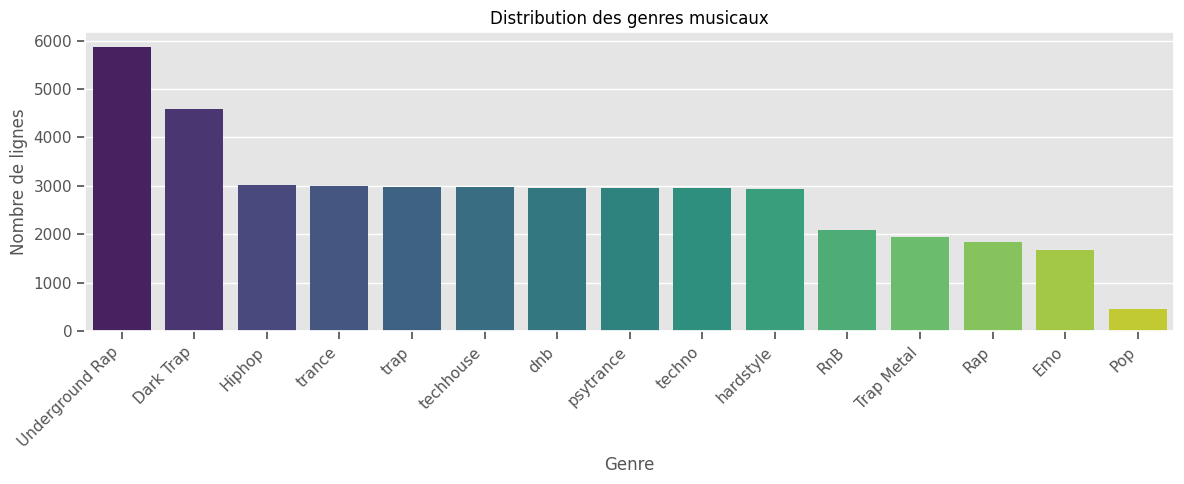

Genre le plus fréquent : Underground Rap (13.9%).
Genre le moins fréquent : Pop (1.1%).


In [5]:
plt.figure(figsize=(12, 5))
sns.barplot(
    x=genre_counts.index,
    y=genre_counts.values,
    hue=genre_counts.index,
    palette="viridis",
    legend=False,
)
plt.xticks(rotation=45, ha="right")
plt.title("Distribution des genres musicaux")
plt.xlabel("Genre")
plt.ylabel("Nombre de lignes")
plt.tight_layout()
plt.savefig("genre_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

print(
    f"Genre le plus fréquent : {genre_counts.index[0]} "
    f"({genre_counts.iloc[0] / len(df):.1%})."
)
print(
    f"Genre le moins fréquent : {genre_counts.index[-1]} "
    f"({genre_counts.iloc[-1] / len(df):.1%})."
)


---
## Phase 3 — Préparation des données

Les variables audio retenues sont numériques et complètes dans ce fichier. L’identifiant est conservé pour éviter qu’une même piste soit répartie entre entraînement et test.


In [6]:
print("=== SÉLECTION DES VARIABLES ===")

required_columns = FEATURES + [TARGET, "id"]
missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f"Colonnes requises absentes : {missing_columns}")

df_clean = df[required_columns].dropna().copy()
df_clean[FEATURES] = df_clean[FEATURES].apply(pd.to_numeric, errors="raise")

print(f"Dataset préparé : {len(df_clean):,} lignes")
print(f"Identifiants de pistes uniques : {df_clean['id'].nunique():,}")
print(f"Lignes écartées pour valeurs manquantes : {len(df) - len(df_clean):,}")
df_clean.head()


=== SÉLECTION DES VARIABLES ===
Dataset préparé : 42,305 lignes
Identifiants de pistes uniques : 35,877
Lignes écartées pour valeurs manquantes : 0


,danceability,energy,loudness,tempo,valence,acousticness,speechiness,instrumentalness,liveness,genre,id
0,0.831,0.814,-7.364,156.985,0.3890,0.0598,0.4200,0.013400,0.0556,Dark Trap,2Vc6NJ9PW9gD9q343XFRKx
1,0.719,0.493,-7.230,115.080,0.1240,0.4010,0.0794,0.000000,0.1180,Dark Trap,7pgJBLVz5VmnL7uGHmRj6p
2,0.850,0.893,-4.783,218.050,0.0391,0.0138,0.0623,0.000004,0.3720,Dark Trap,0vSWgAlfpye0WCGeNmuNhy
3,0.476,0.781,-4.710,186.948,0.1750,0.0237,0.1030,0.000000,0.1140,Dark Trap,0VSXnJqQkwuH2ei1nOQ1nu
4,0.798,0.624,-7.668,147.988,0.5910,0.2170,0.2930,0.000000,0.1660,Dark Trap,4jCeguq9rMTlbMmPHuO7S3


In [7]:
print("=== VÉRIFICATION DES VALEURS MANQUANTES ===")
print(df_clean[FEATURES + [TARGET, "id"]].isnull().sum().to_string())


=== VÉRIFICATION DES VALEURS MANQUANTES ===
danceability        0
energy              0
loudness            0
tempo               0
valence             0
acousticness        0
speechiness         0
instrumentalness    0
liveness            0
genre               0
id                  0


In [8]:
print("=== STANDARDISATION DES VARIABLES AUDIO ===")

X = df_clean[FEATURES]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=FEATURES, index=df_clean.index)

print("StandardScaler : moyenne 0 et écart-type 1 sur les données utilisées ici.")
print("Cette mise à l'échelle globale sert aux analyses exploratoires ACP et K-Means.")
X_scaled_df.head()


=== STANDARDISATION DES VARIABLES AUDIO ===
StandardScaler : moyenne 0 et écart-type 1 sur les données utilisées ici.
Cette mise à l'échelle globale sert aux analyses exploratoires ACP et K-Means.


,danceability,energy,loudness,tempo,valence,acousticness,speechiness,instrumentalness,liveness
0,1.223608,0.280079,-0.305514,0.398876,0.136790,-0.212853,2.246552,-0.727231,-0.902637
1,0.508480,-1.466185,-0.259954,-1.358564,-0.999586,1.784518,-0.453057,-0.763370,-0.547231
2,1.344924,0.709845,0.572039,2.959861,-1.363655,-0.482135,-0.588592,-0.763359,0.899456
3,-1.043093,0.100557,0.596860,1.655485,-0.780887,-0.424181,-0.266002,-0.763370,-0.570013
4,1.012900,-0.753535,-0.408876,0.021554,1.003008,0.707390,1.239945,-0.763370,-0.273841


In [9]:
print(
    "Pour les modèles supervisés, le prétraitement sera ajusté uniquement sur "
    "l'ensemble d'entraînement afin d'éviter une fuite d'information."
)


Pour les modèles supervisés, le prétraitement sera ajusté uniquement sur l'ensemble d'entraînement afin d'éviter une fuite d'information.


---
## Phase 4 — Modélisation
### 4.1 — Analyse en composantes principales (ACP)


In [10]:
# ACP complète — analyse de la variance expliquée
pca_full = PCA()
pca_full.fit(X_scaled)

variance_ratio = pca_full.explained_variance_ratio_
variance_cumul = np.cumsum(variance_ratio)

print("=== VARIANCE EXPLIQUÉE PAR CHAQUE COMPOSANTE ===")
variance_table = pd.DataFrame({
    "Composante": [f"PC{i}" for i in range(1, 10)],
    "Variance expliquée (%)": (variance_ratio * 100).round(2),
    "Variance cumulée (%)": (variance_cumul * 100).round(2)
})
print(variance_table.to_string(index=False))

=== VARIANCE EXPLIQUÉE PAR CHAQUE COMPOSANTE ===
Composante  Variance expliquée (%)  Variance cumulée (%)
       PC1                   25.85                 25.85
       PC2                   19.38                 45.23
       PC3                   14.09                 59.32
       PC4                   10.34                 69.66
       PC5                    8.42                 78.08
       PC6                    8.09                 86.16
       PC7                    6.48                 92.64
       PC8                    5.06                 97.70
       PC9                    2.30                100.00


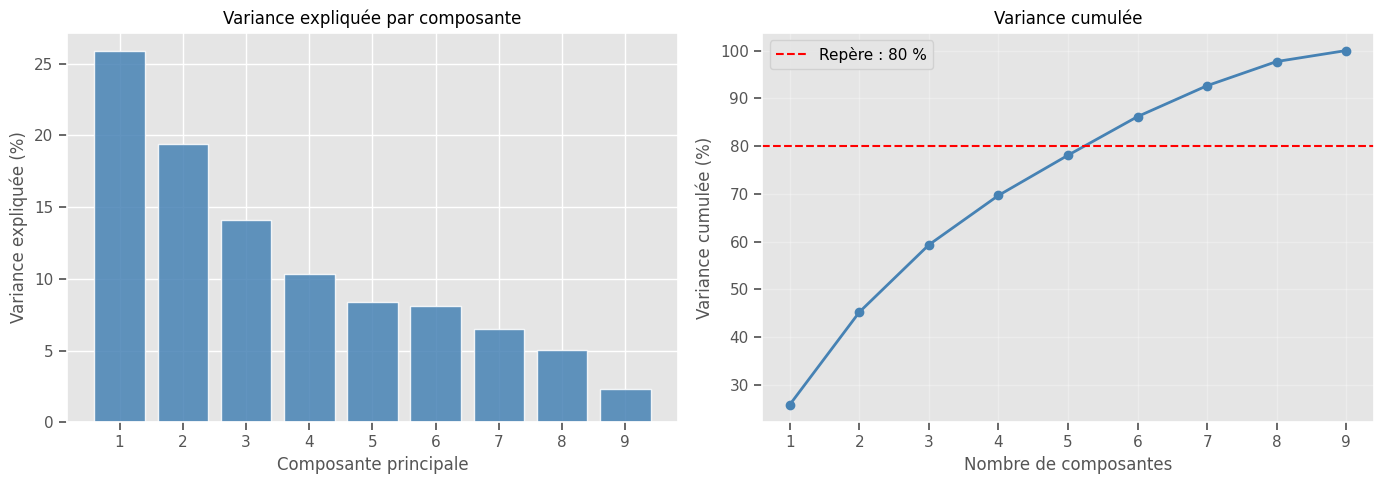

Variance expliquée par les deux premiers axes : 45.23%.
Composantes nécessaires pour atteindre 80 % : 6.


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(
    range(1, len(variance_ratio) + 1),
    variance_ratio * 100,
    color="steelblue",
    alpha=0.85,
    edgecolor="white",
)
axes[0].set_xlabel("Composante principale")
axes[0].set_ylabel("Variance expliquée (%)")
axes[0].set_title("Variance expliquée par composante")
axes[0].set_xticks(range(1, len(variance_ratio) + 1))

axes[1].plot(
    range(1, len(variance_cumul) + 1),
    variance_cumul * 100,
    "o-",
    linewidth=2,
    color="steelblue",
)
axes[1].axhline(y=80, color="red", linestyle="--", label="Repère : 80 %")
axes[1].set_xlabel("Nombre de composantes")
axes[1].set_ylabel("Variance cumulée (%)")
axes[1].set_title("Variance cumulée")
axes[1].set_xticks(range(1, len(variance_cumul) + 1))
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("acp_variance.png", dpi=300, bbox_inches="tight")
plt.show()

n_80 = int(np.searchsorted(variance_cumul, 0.80) + 1)
print(f"Variance expliquée par les deux premiers axes : {variance_cumul[1]:.2%}.")
print(f"Composantes nécessaires pour atteindre 80 % : {n_80}.")


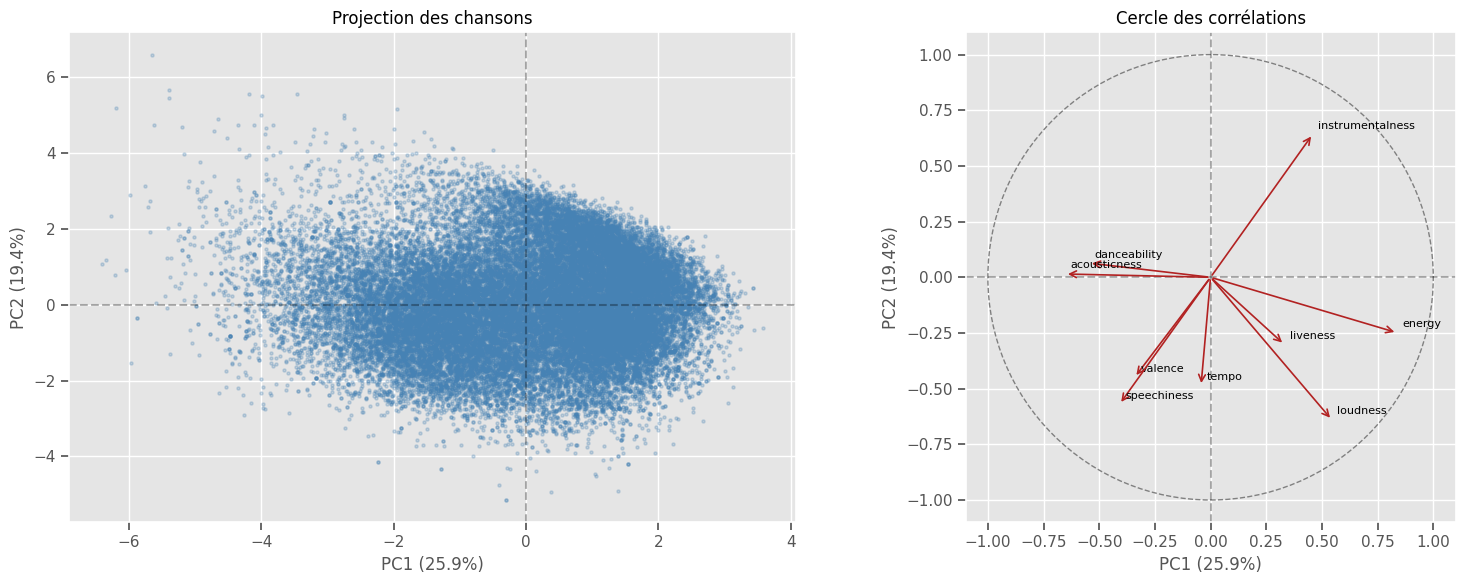

Corrélations estimées des variables avec les deux premiers axes :
                    PC1    PC2
danceability     -0.545  0.064
energy            0.837 -0.249
loudness          0.545 -0.640
tempo            -0.043 -0.487
valence          -0.341 -0.449
acousticness     -0.653  0.015
speechiness      -0.409 -0.570
instrumentalness  0.459  0.643
liveness          0.331 -0.301


In [12]:
# ACP en deux dimensions : projection des chansons et cercle des corrélations
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.25, s=5, color="steelblue")
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
axes[0].set_title("Projection des chansons")
axes[0].axhline(y=0, color="black", linestyle="--", alpha=0.3)
axes[0].axvline(x=0, color="black", linestyle="--", alpha=0.3)

# Corrélations entre variables standardisées et composantes principales.
correlation_loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
circle = plt.Circle((0, 0), 1, fill=False, color="gray", linestyle="--")
axes[1].add_patch(circle)
for i, feature in enumerate(FEATURES):
    x_loading, y_loading = correlation_loadings[i]
    axes[1].annotate(
        "",
        xy=(x_loading, y_loading),
        xytext=(0, 0),
        arrowprops={"arrowstyle": "->", "color": "firebrick", "lw": 1.2},
    )
    axes[1].annotate(
        feature,
        (x_loading, y_loading),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8,
    )

axes[1].set_xlim(-1.1, 1.1)
axes[1].set_ylim(-1.1, 1.1)
axes[1].set_aspect("equal")
axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
axes[1].set_title("Cercle des corrélations")
axes[1].axhline(y=0, color="black", linestyle="--", alpha=0.3)
axes[1].axvline(x=0, color="black", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig("acp_cercle.png", dpi=300, bbox_inches="tight")
plt.show()

loadings = pd.DataFrame(
    correlation_loadings,
    columns=["PC1", "PC2"],
    index=FEATURES,
)
print("Corrélations estimées des variables avec les deux premiers axes :")
print(loadings.round(3))


In [13]:
print("=== INTERPRÉTATION PRUDENTE DE L'ACP ===")
print(
    f"Les deux axes affichés résument {pca.explained_variance_ratio_.sum():.1%} "
    "de la variance : la projection 2D perd donc une partie importante de l'information."
)
print("Les flèches proches indiquent des variables associées dans ce plan ;")
print("des directions opposées suggèrent une association négative dans le plan.")
print("L'orientation des axes (et le signe des composantes) est arbitraire.")
print("L'ACP décrit les données, mais ne démontre pas de causalité.")


=== INTERPRÉTATION PRUDENTE DE L'ACP ===
Les deux axes affichés résument 45.2% de la variance : la projection 2D perd donc une partie importante de l'information.
Les flèches proches indiquent des variables associées dans ce plan ;
des directions opposées suggèrent une association négative dans le plan.
L'orientation des axes (et le signe des composantes) est arbitraire.
L'ACP décrit les données, mais ne démontre pas de causalité.


---
### 4.2 — Segmentation non supervisée : K-Means

Le choix de K reste exploratoire : le coude est un repère visuel et non une preuve d’optimum.


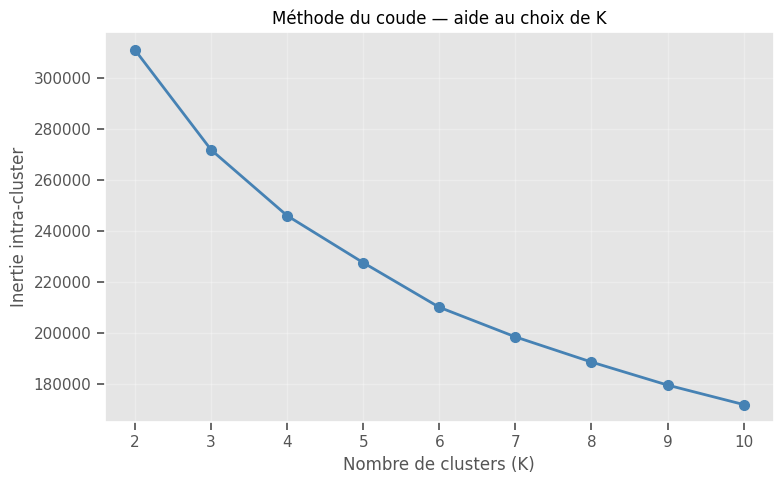

K=3 est retenu pour l'analyse descriptive ; le coude reste une heuristique.


In [14]:
inertias = []
K_range = range(2, 11)

for k in K_range:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, inertias, "o-", linewidth=2, markersize=7, color="steelblue")
plt.xlabel("Nombre de clusters (K)")
plt.ylabel("Inertie intra-cluster")
plt.title("Méthode du coude — aide au choix de K")
plt.xticks(list(K_range))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("elbow.png", dpi=300, bbox_inches="tight")
plt.show()

print("K=3 est retenu pour l'analyse descriptive ; le coude reste une heuristique.")


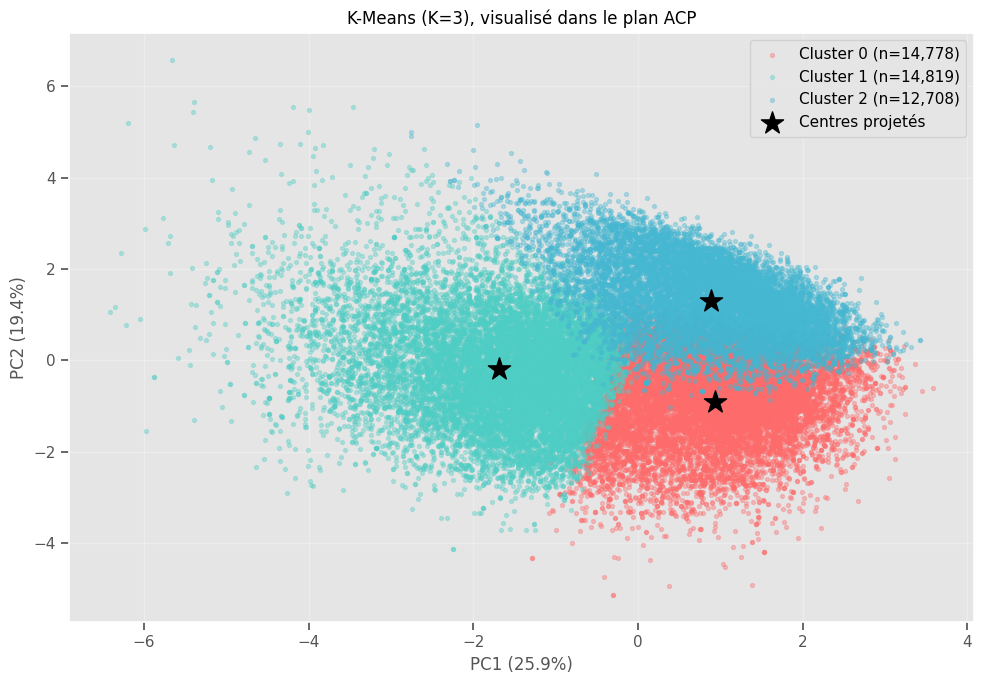

Score de silhouette estimé sur un échantillon : 0.169.
Cette estimation complète le coude sans établir un optimum universel.


In [15]:
kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
clusters = kmeans.fit_predict(X_scaled)
df_clean["Cluster"] = clusters

fig, ax = plt.subplots(figsize=(10, 7))
colors = ["#FF6B6B", "#4ECDC4", "#45B7D1"]
for cluster_id, color in enumerate(colors):
    mask = clusters == cluster_id
    ax.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        c=color,
        label=f"Cluster {cluster_id} (n={mask.sum():,})",
        alpha=0.35,
        s=8,
    )

centers_pca = pca.transform(kmeans.cluster_centers_)
ax.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    c="black",
    marker="*",
    s=280,
    label="Centres projetés",
    zorder=5,
)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
ax.set_title("K-Means (K=3), visualisé dans le plan ACP")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("kmeans_clusters.png", dpi=300, bbox_inches="tight")
plt.show()

silhouette = silhouette_score(
    X_scaled,
    clusters,
    sample_size=min(5000, len(X_scaled)),
    random_state=RANDOM_STATE,
)
print(f"Score de silhouette estimé sur un échantillon : {silhouette:.3f}.")
print("Cette estimation complète le coude sans établir un optimum universel.")


=== PROFIL MOYEN DES CLUSTERS ===


,danceability,energy,loudness,tempo,valence,acousticness,speechiness,instrumentalness,liveness
Cluster,,,,,,,,,
0,0.541,0.873,-4.107,153.285,0.332,0.040,0.140,0.107,0.282
1,0.736,0.588,-7.905,150.091,0.449,0.215,0.197,0.034,0.164
2,0.641,0.838,-7.529,137.666,0.279,0.024,0.063,0.778,0.193



=== TAILLE DES CLUSTERS ===


Cluster
0    14778
1    14819
2    12708
Name: count, dtype: int64

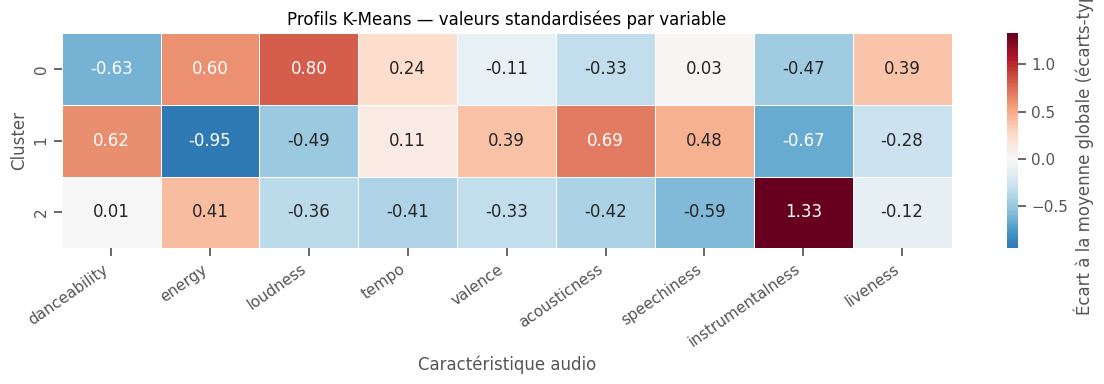

In [16]:
cluster_profile = df_clean.groupby("Cluster")[FEATURES].mean()
cluster_profile_z = (cluster_profile - scaler.mean_) / scaler.scale_

print("=== PROFIL MOYEN DES CLUSTERS ===")
display(cluster_profile.round(3))
print("\n=== TAILLE DES CLUSTERS ===")
display(df_clean["Cluster"].value_counts().sort_index())

plt.figure(figsize=(12, 4))
sns.heatmap(
    cluster_profile_z,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Écart à la moyenne globale (écarts-types)"},
)
plt.title("Profils K-Means — valeurs standardisées par variable")
plt.xlabel("Caractéristique audio")
plt.ylabel("Cluster")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig("cluster_profiles.png", dpi=300, bbox_inches="tight")
plt.show()


In [17]:
print("=== GENRES LES PLUS FRÉQUENTS PAR CLUSTER ===")
for cluster_id in sorted(df_clean["Cluster"].unique()):
    print(f"\n--- Cluster {cluster_id} ---")
    genre_dist = (
        df_clean.loc[df_clean["Cluster"] == cluster_id, TARGET]
        .value_counts()
        .head(5)
    )
    print(genre_dist.to_string())

print("\nLes numéros de cluster sont arbitraires ; les profils moyens et genres")
print("dominants servent à les décrire, sans supposer qu'un cluster égale un genre.")


=== GENRES LES PLUS FRÉQUENTS PAR CLUSTER ===

--- Cluster 0 ---
genre
hardstyle    2619
trap         2617
dnb          1971
Emo          1232
trance       1173

--- Cluster 1 ---
genre
Underground Rap    4710
Hiphop             2295
Dark Trap          2242
RnB                1679
Rap                1581

--- Cluster 2 ---
genre
techno       2868
psytrance    2758
techhouse    2255
trance       1764
Dark Trap    1271

Les numéros de cluster sont arbitraires ; les profils moyens et genres
dominants servent à les décrire, sans supposer qu'un cluster égale un genre.


In [18]:
print("=== DISTRIBUTION DES GENRES DANS CHAQUE CLUSTER ===")
for cluster_id in cluster_profile.index:
    cluster_mask = df_clean["Cluster"] == cluster_id
    genre_dist = df_clean.loc[cluster_mask, TARGET].value_counts().head(5)
    print(f"\n--- Cluster {cluster_id} ---")
    print(genre_dist.to_string())

feature_labels = {
    "danceability": "dansabilité",
    "energy": "énergie",
    "loudness": "niveau sonore",
    "tempo": "tempo",
    "valence": "valence",
    "acousticness": "caractère acoustique",
    "speechiness": "contenu parlé",
    "instrumentalness": "caractère instrumental",
    "liveness": "caractère live",
}

print("\n=== INTERPRÉTATION CALCULÉE DES CLUSTERS ===")
for cluster_id in cluster_profile.index:
    profile = cluster_profile.loc[cluster_id]
    standardized_profile = cluster_profile_z.loc[cluster_id]
    high_features = standardized_profile.nlargest(3)
    low_features = standardized_profile.nsmallest(2)
    cluster_mask = df_clean["Cluster"] == cluster_id
    cluster_size = int(cluster_mask.sum())
    genre_dist = df_clean.loc[cluster_mask, TARGET].value_counts().head(3)

    print(f"\nCluster {cluster_id} ({cluster_size:,} chansons)")
    print("Caractéristiques au-dessus de la moyenne globale :")
    for feature, z_score in high_features.items():
        value = profile[feature]
        print(
            f"  - {feature_labels[feature]} : moyenne {value:.3f} "
            f"({z_score:+.2f} écart-type)"
        )
    print("Caractéristiques en dessous de la moyenne globale :")
    for feature, z_score in low_features.items():
        value = profile[feature]
        print(
            f"  - {feature_labels[feature]} : moyenne {value:.3f} "
            f"({z_score:+.2f} écart-type)"
        )
    genre_summary = ", ".join(
        f"{genre} ({count / cluster_size:.1%})"
        for genre, count in genre_dist.items()
    )
    print(f"Genres les plus fréquents : {genre_summary}")


=== DISTRIBUTION DES GENRES DANS CHAQUE CLUSTER ===

--- Cluster 0 ---
genre
hardstyle    2619
trap         2617
dnb          1971
Emo          1232
trance       1173

--- Cluster 1 ---
genre
Underground Rap    4710
Hiphop             2295
Dark Trap          2242
RnB                1679
Rap                1581

--- Cluster 2 ---
genre
techno       2868
psytrance    2758
techhouse    2255
trance       1764
Dark Trap    1271

=== INTERPRÉTATION CALCULÉE DES CLUSTERS ===

Cluster 0 (14,778 chansons)
Caractéristiques au-dessus de la moyenne globale :
  - niveau sonore : moyenne -4.107 (+0.80 écart-type)
  - énergie : moyenne 0.873 (+0.60 écart-type)
  - caractère live : moyenne 0.282 (+0.39 écart-type)
Caractéristiques en dessous de la moyenne globale :
  - dansabilité : moyenne 0.541 (-0.63 écart-type)
  - caractère instrumental : moyenne 0.107 (-0.47 écart-type)
Genres les plus fréquents : hardstyle (17.7%), trap (17.7%), dnb (13.3%)

Cluster 1 (14,819 chansons)
Caractéristiques au-dessu

---
### 4.3 — Corrélations

Une corrélation décrit une association linéaire entre deux variables ; elle n’établit ni causalité ni direction d’influence.


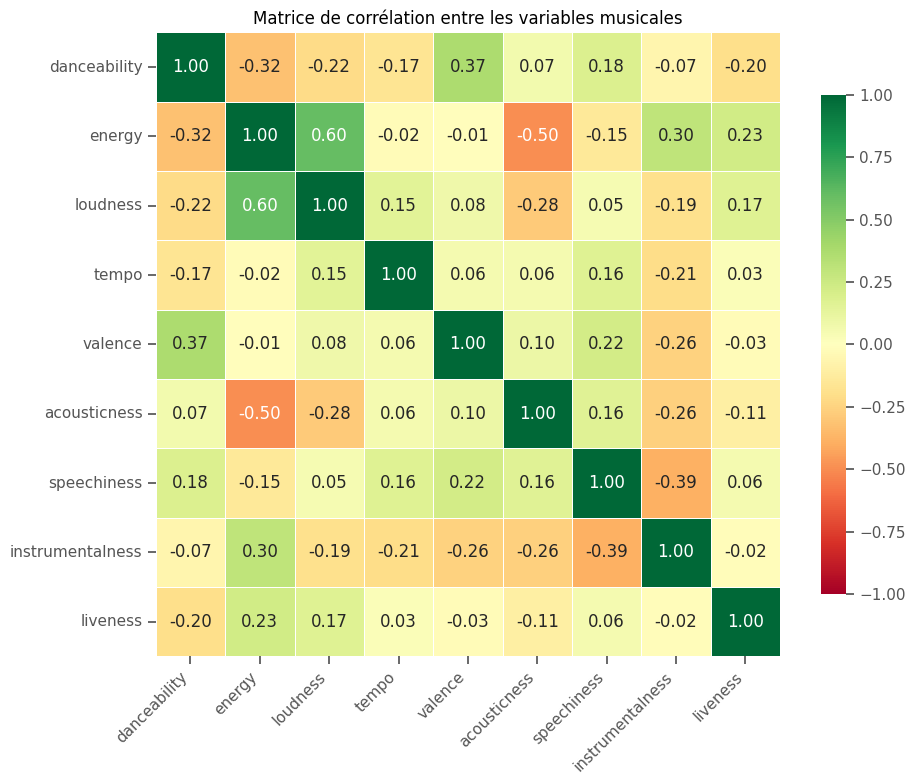

In [19]:
plt.figure(figsize=(10, 8))
corr_matrix = df_clean[FEATURES].corr()
sns.heatmap(
    corr_matrix, annot=True, fmt=".2f",
    cmap="RdYlGn", center=0, vmin=-1, vmax=1,
    square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}
)
plt.title("Matrice de corrélation entre les variables musicales", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("correlation.png", dpi=300, bbox_inches='tight')
plt.show()

In [20]:
print("=== PAIRES DE VARIABLES LES PLUS CORRÉLÉES ===")
corr_pairs = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
).stack()
for (var1, var2), value in corr_pairs.reindex(
    corr_pairs.abs().sort_values(ascending=False).index
).head(10).items():
    print(f"{var1} ↔ {var2} : {value:.3f}")

print("\nInterpréter ces valeurs comme des associations, et non comme des effets causaux.")


=== PAIRES DE VARIABLES LES PLUS CORRÉLÉES ===
energy ↔ loudness : 0.602
energy ↔ acousticness : -0.497
speechiness ↔ instrumentalness : -0.387
danceability ↔ valence : 0.370
danceability ↔ energy : -0.323
energy ↔ instrumentalness : 0.304
loudness ↔ acousticness : -0.284
acousticness ↔ instrumentalness : -0.262
valence ↔ instrumentalness : -0.257
energy ↔ liveness : 0.232

Interpréter ces valeurs comme des associations, et non comme des effets causaux.


---
### 4.4 — Régression linéaire

La cible est `loudness`. La séparation est faite par identifiant de piste ; le scaler est ajusté dans le pipeline uniquement sur le train. Les coefficients standardisés facilitent la comparaison de l’association linéaire entre prédicteurs.


In [21]:
REG_FEATURES = [
    "energy", "acousticness", "speechiness", "tempo",
    "danceability", "liveness", "valence", "instrumentalness",
]

X_reg = df_clean[REG_FEATURES]
y_reg = df_clean["loudness"]
reg_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=RANDOM_STATE,
)
reg_train_idx, reg_test_idx = next(
    reg_splitter.split(X_reg, y_reg, groups=df_clean["id"])
)
X_reg_train, X_reg_test = X_reg.iloc[reg_train_idx], X_reg.iloc[reg_test_idx]
y_reg_train, y_reg_test = y_reg.iloc[reg_train_idx], y_reg.iloc[reg_test_idx]

reg = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("linear_regression", LinearRegression()),
    ]
)
reg.fit(X_reg_train, y_reg_train)
y_reg_pred = reg.predict(X_reg_test)

r2 = r2_score(y_reg_test, y_reg_pred)
rmse = np.sqrt(mean_squared_error(y_reg_test, y_reg_pred))
reg_coefficients = reg.named_steps["linear_regression"].coef_
coef_df = (
    pd.DataFrame({"Variable": REG_FEATURES, "Coefficient standardisé": reg_coefficients})
    .sort_values("Coefficient standardisé", ascending=False)
)

print("=== ÉVALUATION DE LA RÉGRESSION ===")
print(f"R² sur le test : {r2:.4f}")
print(f"RMSE sur le test : {rmse:.3f} dB")
print(f"Référence train (prédiction de la moyenne) : "
      f"{np.sqrt(mean_squared_error(y_reg_test, np.full(len(y_reg_test), y_reg_train.mean()))):.3f} dB")
print("\nCoefficients sur les variables standardisées :")
print(coef_df.to_string(index=False))


=== ÉVALUATION DE LA RÉGRESSION ===
R² sur le test : 0.5159
RMSE sur le test : 2.047 dB
Référence train (prédiction de la moyenne) : 2.943 dB

Coefficients sur les variables standardisées :
        Variable  Coefficient standardisé
          energy                 2.086780
           tempo                 0.277595
    danceability                 0.031513
        liveness                -0.026088
     speechiness                -0.027463
         valence                -0.044555
    acousticness                -0.118428
instrumentalness                -1.193743


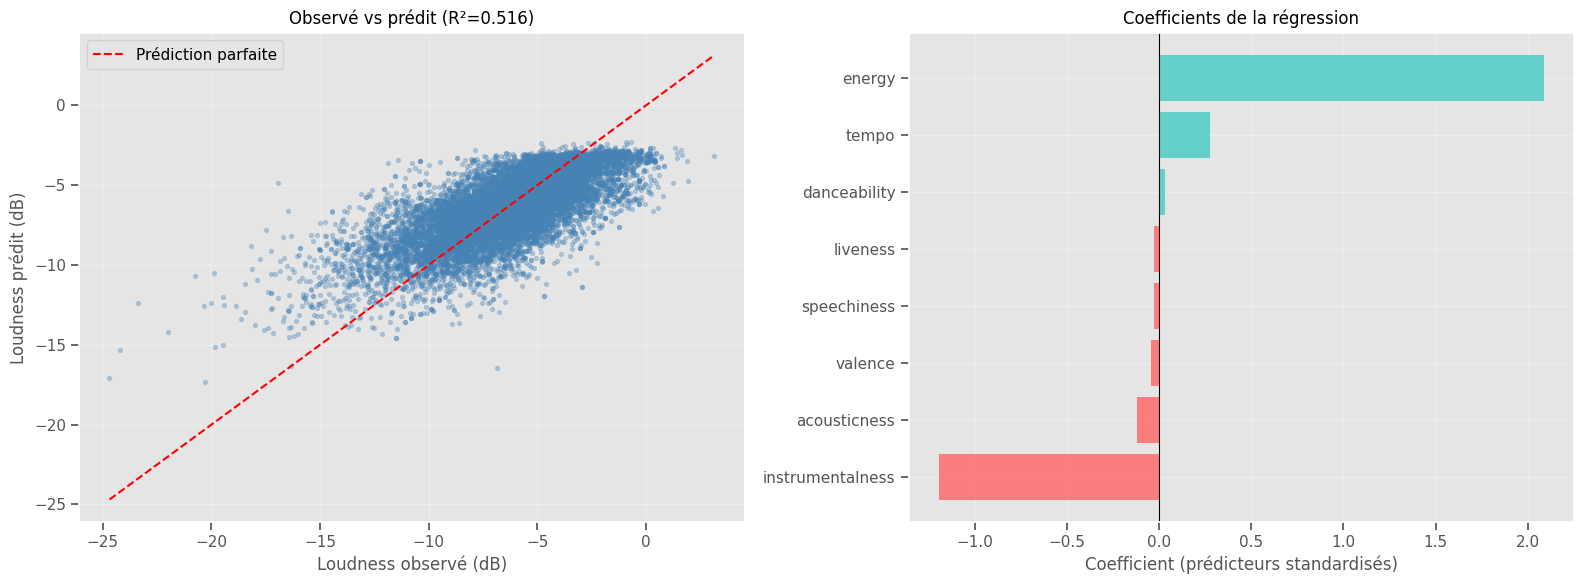

Les coefficients décrivent une association conditionnelle dans ce modèle ;
ils ne démontrent pas d'effet causal.


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].scatter(y_reg_test, y_reg_pred, alpha=0.3, s=8, color="steelblue")
line_min = min(y_reg_test.min(), y_reg_pred.min())
line_max = max(y_reg_test.max(), y_reg_pred.max())
axes[0].plot([line_min, line_max], [line_min, line_max], "r--", label="Prédiction parfaite")
axes[0].set_xlabel("Loudness observé (dB)")
axes[0].set_ylabel("Loudness prédit (dB)")
axes[0].set_title(f"Observé vs prédit (R²={r2:.3f})")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

coef_sorted = coef_df.sort_values("Coefficient standardisé")
coef_colors = [
    "#FF6B6B" if value < 0 else "#4ECDC4"
    for value in coef_sorted["Coefficient standardisé"]
]
axes[1].barh(
    coef_sorted["Variable"],
    coef_sorted["Coefficient standardisé"],
    color=coef_colors,
    alpha=0.85,
)
axes[1].axvline(x=0, color="black", linewidth=0.8)
axes[1].set_xlabel("Coefficient (prédicteurs standardisés)")
axes[1].set_title("Coefficients de la régression")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("regression_results.png", dpi=300, bbox_inches="tight")
plt.show()

print("Les coefficients décrivent une association conditionnelle dans ce modèle ;")
print("ils ne démontrent pas d'effet causal.")


---
### 4.5 — Classification supervisée : LDA et arbre de décision

L’évaluation est limitée aux cinq genres les plus représentés. Les identifiants apparaissant sous plusieurs genres dans le CSV complet sont retirés ; la séparation est ensuite faite par groupe d’identifiant pour empêcher une piste répétée de se retrouver des deux côtés.


In [23]:
top_genres = df_clean[TARGET].value_counts().head(5).index.tolist()
genres_per_track = df_clean.groupby("id")[TARGET].nunique()
ambiguous_ids = genres_per_track[genres_per_track > 1].index
df_classification = df_clean.loc[
    ~df_clean["id"].isin(ambiguous_ids)
    & df_clean[TARGET].isin(top_genres)
].copy()

print("=== PRÉPARATION DE LA CLASSIFICATION ===")
print(f"Genres évalués : {top_genres}")
print(f"Identifiants ambigus exclus : {len(ambiguous_ids):,}")
print(f"Lignes de ces cinq genres après exclusion : {len(df_classification):,}")
print(f"Identifiants uniques retenus : {df_classification['id'].nunique():,}")
print("\nEffectifs par genre :")
display(df_classification[TARGET].value_counts().sort_index())

le = LabelEncoder()
y = le.fit_transform(df_classification[TARGET])
X_cls = df_classification[FEATURES]
groups = df_classification["id"].to_numpy()

cls_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=RANDOM_STATE,
)
train_idx, test_idx = next(cls_splitter.split(X_cls, y, groups=groups))
X_train, X_test = X_cls.iloc[train_idx], X_cls.iloc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
groups_train, groups_test = groups[train_idx], groups[test_idx]

assert set(groups_train).isdisjoint(groups_test), "Une piste apparaît dans train et test."
print(f"\nTrain : {len(X_train):,} lignes | Test : {len(X_test):,} lignes")
print(f"Identifiants partagés entre train et test : {len(set(groups_train) & set(groups_test))}")


=== PRÉPARATION DE LA CLASSIFICATION ===
Genres évalués : ['Underground Rap', 'Dark Trap', 'Hiphop', 'trance', 'trap']
Identifiants ambigus exclus : 2,520
Lignes de ces cinq genres après exclusion : 15,813
Identifiants uniques retenus : 14,995

Effectifs par genre :


genre
Dark Trap          3590
Hiphop             2328
Underground Rap    3917
trance             2994
trap               2984
Name: count, dtype: int64


Train : 11,072 lignes | Test : 4,741 lignes
Identifiants partagés entre train et test : 0


In [24]:
lda = LinearDiscriminantAnalysis()
lda.fit(X_train, y_train)
y_pred_lda = lda.predict(X_test)
acc_lda = accuracy_score(y_test, y_pred_lda)
macro_f1_lda = f1_score(y_test, y_pred_lda, average="macro")
majority_class = np.bincount(y_train).argmax()
baseline_accuracy = accuracy_score(y_test, np.full(len(y_test), majority_class))

print("=== RÉSULTATS DE LA LDA ===")
print(f"Accuracy : {acc_lda:.3f}")
print(f"F1 macro : {macro_f1_lda:.3f}")
print(f"Référence majoritaire (train) : {baseline_accuracy:.3f} accuracy")
print("\nRapport de classification :")
print(
    classification_report(
        y_test,
        y_pred_lda,
        labels=np.arange(len(le.classes_)),
        target_names=le.classes_,
        zero_division=0,
    )
)


=== RÉSULTATS DE LA LDA ===
Accuracy : 0.651
F1 macro : 0.640
Référence majoritaire (train) : 0.249 accuracy

Rapport de classification :
                 precision    recall  f1-score   support

      Dark Trap       0.61      0.50      0.55      1049
         Hiphop       0.50      0.42      0.45       696
Underground Rap       0.59      0.65      0.62      1180
         trance       0.75      0.83      0.79       925
           trap       0.75      0.83      0.79       891

       accuracy                           0.65      4741
      macro avg       0.64      0.64      0.64      4741
   weighted avg       0.64      0.65      0.64      4741



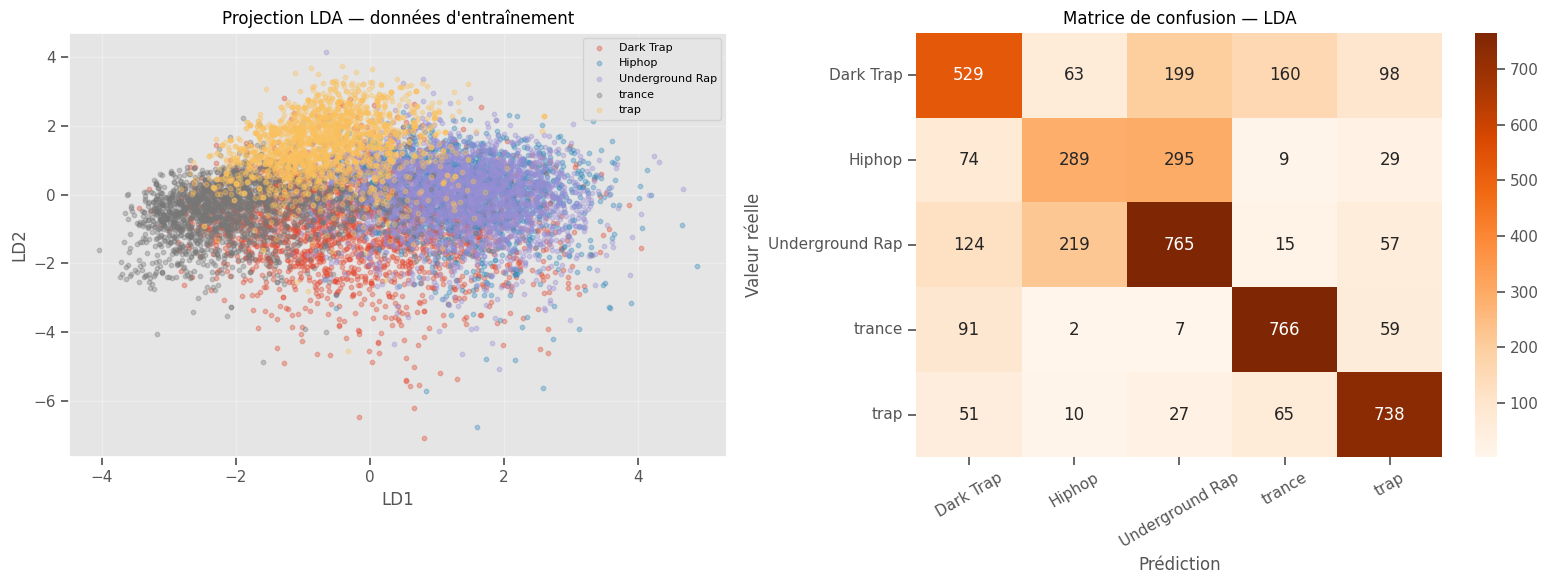

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

X_lda = lda.transform(X_train)
for class_id, genre in enumerate(le.classes_):
    mask = y_train == class_id
    second_axis = X_lda[mask, 1] if X_lda.shape[1] > 1 else np.zeros(mask.sum())
    axes[0].scatter(
        X_lda[mask, 0],
        second_axis,
        label=genre,
        alpha=0.35,
        s=10,
    )
axes[0].set_xlabel("LD1")
axes[0].set_ylabel("LD2" if X_lda.shape[1] > 1 else "Axe nul (une seule composante)")
axes[0].set_title("Projection LDA — données d'entraînement")
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.3)

cm_lda = confusion_matrix(y_test, y_pred_lda, labels=np.arange(len(le.classes_)))
sns.heatmap(
    cm_lda,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=le.classes_,
    yticklabels=le.classes_,
    ax=axes[1],
)
axes[1].set_xlabel("Prédiction")
axes[1].set_ylabel("Valeur réelle")
axes[1].set_title("Matrice de confusion — LDA")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig("lda_results.png", dpi=300, bbox_inches="tight")
plt.show()


---
### 4.6 — Arbre de décision

La profondeur est limitée à 4 pour faciliter l’interprétation. Le schéma, les métriques et les importances concernent le même modèle.


In [26]:
dt = DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)
dt.fit(X_train, y_train)
y_pred = dt.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
macro_f1_tree = f1_score(y_test, y_pred, average="macro")

print("=== RÉSULTATS DE L'ARBRE DE DÉCISION ===")
print(f"Accuracy : {accuracy:.3f}")
print(f"F1 macro : {macro_f1_tree:.3f}")
print("\nRapport de classification :")
print(
    classification_report(
        y_test,
        y_pred,
        labels=np.arange(len(le.classes_)),
        target_names=le.classes_,
        zero_division=0,
    )
)


=== RÉSULTATS DE L'ARBRE DE DÉCISION ===
Accuracy : 0.638
F1 macro : 0.624

Rapport de classification :
                 precision    recall  f1-score   support

      Dark Trap       0.60      0.48      0.53      1049
         Hiphop       0.37      0.36      0.36       696
Underground Rap       0.59      0.61      0.60      1180
         trance       0.73      0.84      0.78       925
           trap       0.82      0.86      0.84       891

       accuracy                           0.64      4741
      macro avg       0.62      0.63      0.62      4741
   weighted avg       0.63      0.64      0.63      4741



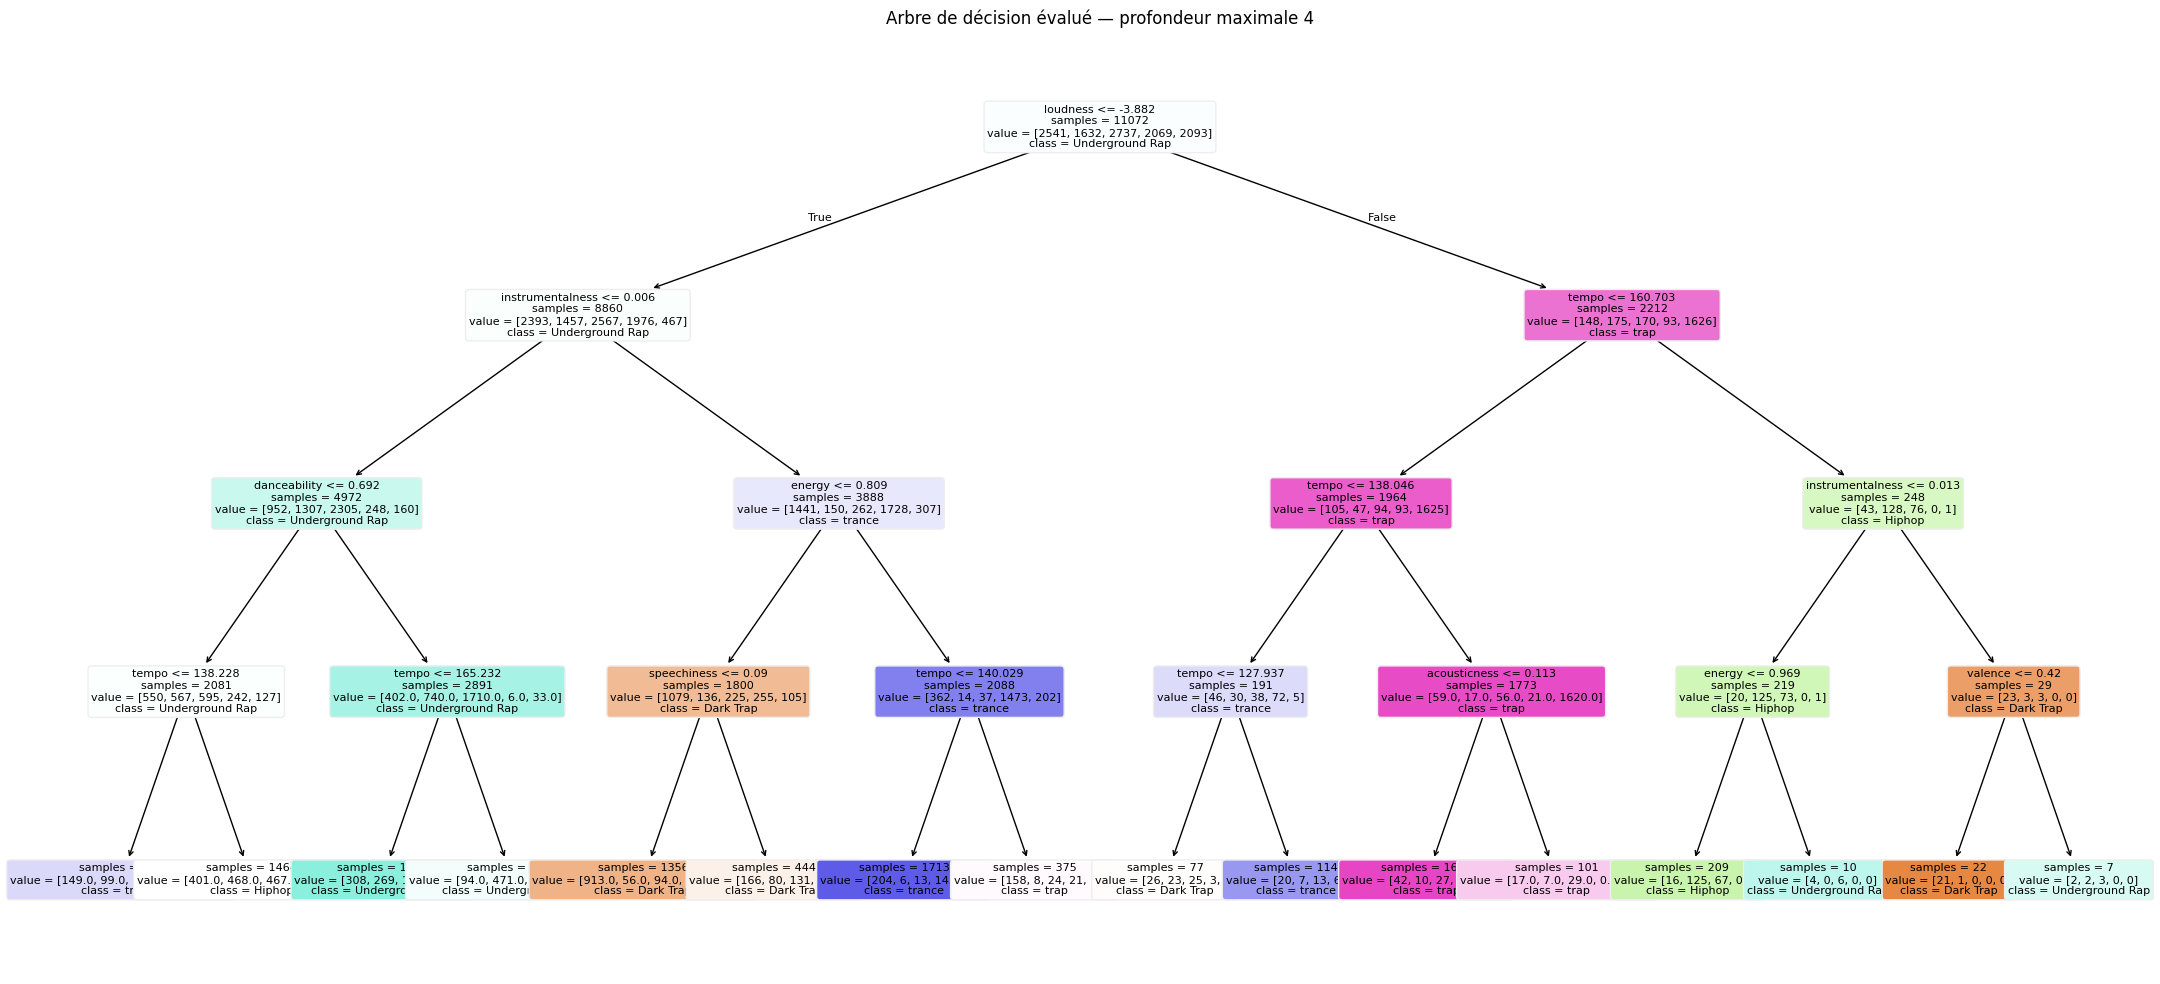

In [27]:
plt.figure(figsize=(22, 10))
plot_tree(
    dt,
    feature_names=FEATURES,
    class_names=le.classes_,
    filled=True,
    rounded=True,
    fontsize=8,
    impurity=False,
)
plt.title("Arbre de décision évalué — profondeur maximale 4")
plt.tight_layout()
plt.savefig("decision_tree.png", dpi=300, bbox_inches="tight")
plt.show()


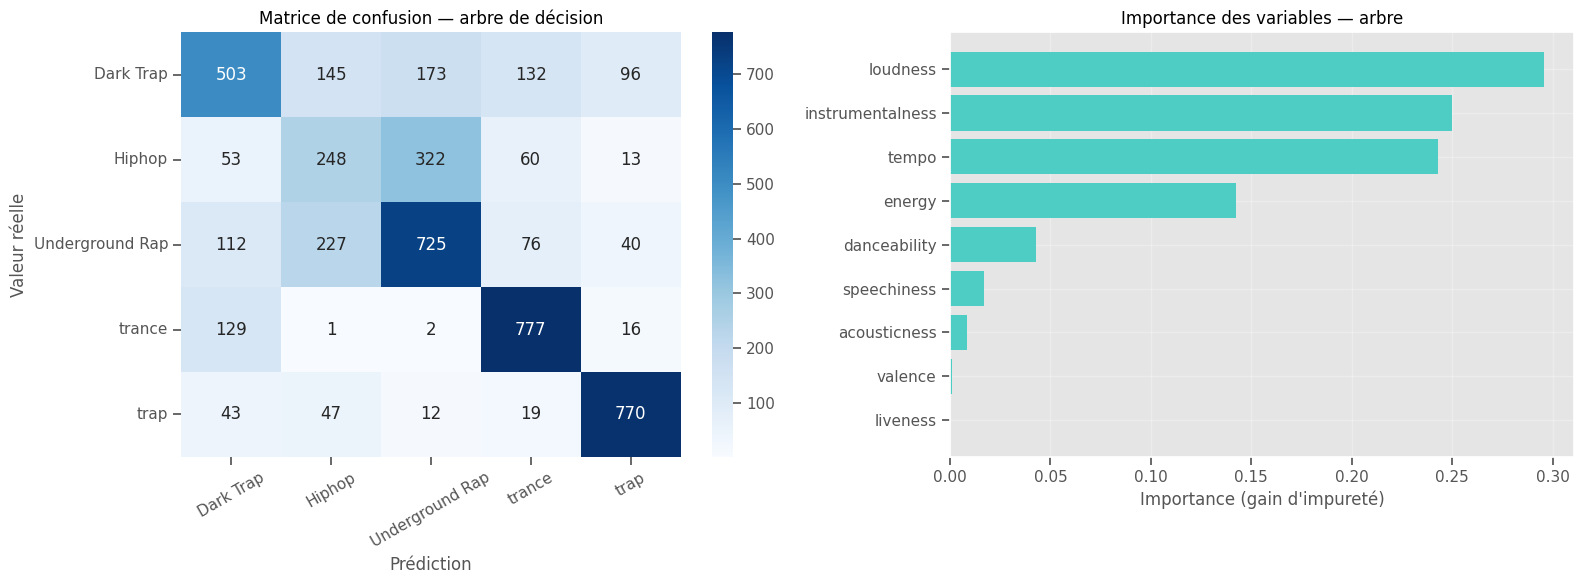

=== IMPORTANCE DES VARIABLES ===
        Variable  Importance
        loudness    0.295807
instrumentalness    0.250082
           tempo    0.242698
          energy    0.142504
    danceability    0.042622
     speechiness    0.016810
    acousticness    0.008446
         valence    0.001032
        liveness    0.000000

L'importance décrit la contribution aux divisions de cet arbre précis ;
elle ne mesure pas un effet causal.


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cm = confusion_matrix(y_test, y_pred, labels=np.arange(len(le.classes_)))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=le.classes_,
    yticklabels=le.classes_,
    ax=axes[0],
)
axes[0].set_xlabel("Prédiction")
axes[0].set_ylabel("Valeur réelle")
axes[0].set_title("Matrice de confusion — arbre de décision")
axes[0].tick_params(axis="x", rotation=30)

importances = (
    pd.DataFrame({"Variable": FEATURES, "Importance": dt.feature_importances_})
    .sort_values("Importance", ascending=True)
)
axes[1].barh(importances["Variable"], importances["Importance"], color="#4ECDC4")
axes[1].set_xlabel("Importance (gain d'impureté)")
axes[1].set_title("Importance des variables — arbre")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("tree_results.png", dpi=300, bbox_inches="tight")
plt.show()

print("=== IMPORTANCE DES VARIABLES ===")
print(importances.sort_values("Importance", ascending=False).to_string(index=False))
print("\nL'importance décrit la contribution aux divisions de cet arbre précis ;")
print("elle ne mesure pas un effet causal.")


---
## Phase 5 — Évaluation des résultats

Les métriques ci-dessous sont recalculées sur un test séparé par identifiant de piste. Accuracy et F1 macro sont complémentaires : le F1 macro donne le même poids à chaque genre.


In [29]:
results = pd.DataFrame(
    {
        "Méthode": [
            "ACP", "K-Means", "Corrélations",
            "Régression linéaire", "LDA", "Arbre de décision",
        ],
        "Résultat principal": [
            f"{variance_cumul[1]:.1%} de variance sur les deux premiers axes",
            f"Silhouette estimée (K=3) : {silhouette:.3f}",
            f"energy ↔ loudness : {corr_matrix.loc['energy', 'loudness']:.3f}",
            f"R²={r2:.3f} ; RMSE={rmse:.3f} dB",
            f"Accuracy={acc_lda:.3f} ; F1 macro={macro_f1_lda:.3f}",
            f"Accuracy={accuracy:.3f} ; F1 macro={macro_f1_tree:.3f}",
        ],
        "Lecture": [
            "Projection 2D à interpréter avec prudence",
            "Segmentation descriptive, K choisi par heuristique",
            "Association, sans conclusion causale",
            "Comparer au modèle de référence",
            "Évaluer par genre et comparer au baseline",
            "Interprétable, profondeur limitée à 4",
        ],
    }
)
display(results)
print(
    "\nLa classification couvre cinq genres et exclut les pistes aux étiquettes "
    "contradictoires ; ses scores ne se généralisent pas automatiquement aux "
    "15 genres du jeu de données."
)


,Méthode,Résultat principal,Lecture
0,ACP,45.2% de variance sur les deux premiers axes,Projection 2D à interpréter avec prudence
1,K-Means,Silhouette estimée (K=3) : 0.169,"Segmentation descriptive, K choisi par heurist..."
2,Corrélations,energy ↔ loudness : 0.602,"Association, sans conclusion causale"
3,Régression linéaire,R²=0.516 ; RMSE=2.047 dB,Comparer au modèle de référence
4,LDA,Accuracy=0.651 ; F1 macro=0.640,Évaluer par genre et comparer au baseline
5,Arbre de décision,Accuracy=0.638 ; F1 macro=0.624,"Interprétable, profondeur limitée à 4"



La classification couvre cinq genres et exclut les pistes aux étiquettes contradictoires ; ses scores ne se généralisent pas automatiquement aux 15 genres du jeu de données.


## Phase 6 — Conclusion et perspectives

### Bilan

- Le jeu de données contient 42 305 lignes, 22 colonnes et 15 genres. Certaines colonnes de métadonnées sont incomplètes, mais les neuf variables audio sélectionnées sont renseignées.
- L’ACP résume les profils audio ; les deux premiers axes ne retiennent qu’une partie de la variance et ne suffisent pas à représenter toute la structure.
- K-Means produit trois groupes décrits par leurs profils audio moyens. Le choix de trois groupes reste une décision exploratoire, fondée sur le coude et accompagnée d’une silhouette échantillonnée.
- Les corrélations mettent en évidence des associations entre variables, sans établir de causalité.
- La régression estime `loudness` sur un test séparé par piste et se compare à une prédiction de référence.
- LDA et l’arbre sont évalués sur cinq genres. Les pistes ayant plusieurs genres dans le fichier complet sont écartées de cette classification et les pistes répétées sont gardées dans un même ensemble.

### Limites

- La classification n’inclut pas les 15 genres et ses résultats dépendent de la sélection des genres et du découpage.
- Le fichier peut contenir des pistes répétées ; le split groupé évite leur présence simultanée dans train et test, mais les métriques restent pondérées par le nombre de lignes.
- L’évaluation est une seule séparation aléatoire, non une validation croisée.
- Les variables audio et les labels de genre proviennent du jeu de données ; la qualité et la signification de ces labels ne sont pas vérifiées indépendamment.
- Aucun déploiement applicatif n’est réalisé : dans CRISP-DM, cette étape reste hors périmètre.

### Pistes d’amélioration raisonnables

1. Documenter la source et la licence des données.
2. Tester une validation croisée groupée avant toute comparaison définitive des modèles.
3. Comparer les scores par genre avec le baseline et examiner les erreurs de classification.
4. Réexporter le PDF et les graphiques après chaque exécution complète.

Les résultats chiffrés doivent être lus dans les cellules exécutées ci-dessus ; aucune performance n’est supposée à l’avance.
